In [11]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import polars as pl
import numpy as np

print(sys.executable)
print(pl.__version__)

c:\Users\zonam\Documents\GitHub\origination-model-stats\.venv\Scripts\python.exe
2.2.0


In [2]:
actual = Path.cwd()
raiz = next(p for p in (actual, *actual.parents) if (p / "pyproject.toml").is_file())
datos = raiz / "src" / "data"

train = pl.read_csv(datos / "credito_2008_2013_train.csv", try_parse_dates=True)
test = pl.read_csv(datos / "credito_2008_2013_test.csv", try_parse_dates=True)
validation = pl.read_csv(datos / "credito_2008_2013_validation.csv", try_parse_dates=True)

print(f"Train:      {train.height:,}")
print(f"Test:       {test.height:,}")
print(f"Validation: {validation.height:,}")

Train:      92,095
Test:       32,125
Validation: 10,350


In [4]:
monitoreo = pl.concat([
    test.with_columns(pl.lit("test").alias("conjunto")),
    validation.with_columns(pl.lit("validation").alias("conjunto")),
])

resumen_mensual = (
    monitoreo
    .group_by("issue_d", "conjunto")
    .agg(
        pl.len().alias("n_prestamos"),
        pl.col("loan_status").sum().alias("n_incumplidos"),
    )
    .with_columns(
        (100 * pl.col("n_incumplidos") / pl.col("n_prestamos"))
        .round(2)
        .alias("tasa_incumplimiento_pct")
    )
    .sort("issue_d")
)

resumen_mensual

issue_d,conjunto,n_prestamos,n_incumplidos,tasa_incumplimiento_pct
date,str,u32,i64,f64
2013-01-01,"""test""",6872,1050,15.28
2013-02-01,"""test""",7561,1160,15.34
2013-03-01,"""test""",8273,1200,14.51
2013-04-01,"""test""",9419,1504,15.97
2013-05-01,"""validation""",10350,1720,16.62


In [ ]:
train.columns

In [8]:

conjuntos = ["train", "test", "validation"]
columnas = ["issue_d", "loan_status", "loan_amnt", "dti"]

partes = []
for conjunto in conjuntos:
    archivo = datos / f"credito_2008_2013_{conjunto}.csv"
    parte = pl.read_csv(archivo, columns=columnas, try_parse_dates=True)
    partes.append(parte.with_columns(pl.lit(conjunto).alias("conjunto")))

prestamos = pl.concat(partes)

tabla_mensual = (
    prestamos
    .group_by("issue_d", "conjunto")
    .agg(
        pl.len().alias("n_prestamos"),
        pl.col("loan_status").sum().alias("n_incumplidos"),
    )
    .with_columns(
        (100 * pl.col("n_incumplidos") / pl.col("n_prestamos"))
        .round(2)
        .alias("tasa_incumplimiento_pct")
    )
    .rename({"issue_d": "mes_emision"})
    .sort("mes_emision")
)

tabla_mensual.write_csv(datos / "resumen_mensual_credito.csv")
tabla_mensual

mes_emision,conjunto,n_prestamos,n_incumplidos,tasa_incumplimiento_pct
date,str,u32,i64,f64
2008-06-01,"""train""",66,7,10.61
2008-07-01,"""train""",83,17,20.48
2008-08-01,"""train""",71,6,8.45
2008-09-01,"""train""",32,5,15.62
2008-10-01,"""train""",96,15,15.62
…,…,…,…,…
2013-01-01,"""test""",6872,1050,15.28
2013-02-01,"""test""",7561,1160,15.34
2013-03-01,"""test""",8273,1200,14.51


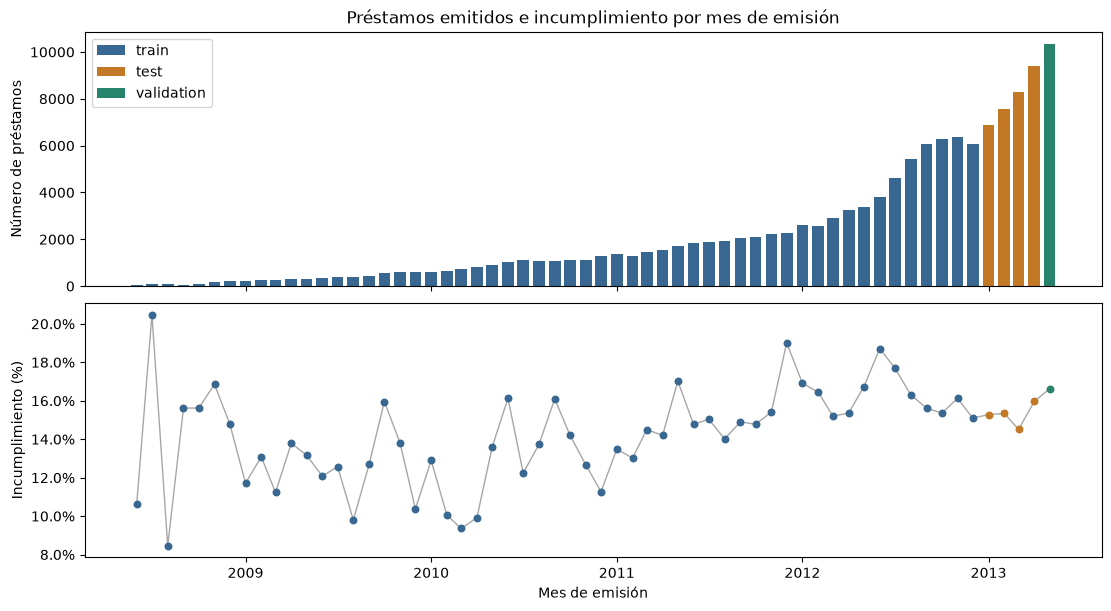

In [12]:

colores = {
    "train": "#386891",
    "test": "#C27824",
    "validation": "#28836C",
}

fig, (ax_n, ax_tasa) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, layout="constrained"
)

ax_tasa.plot(
    tabla_mensual["mes_emision"].to_list(),
    tabla_mensual["tasa_incumplimiento_pct"].to_numpy(),
    color="0.65",
    linewidth=1,
    zorder=1,
)

for conjunto in conjuntos:
    grupo = tabla_mensual.filter(pl.col("conjunto") == conjunto)
    meses = grupo["mes_emision"].to_list()

    ax_n.bar(
        meses, grupo["n_prestamos"].to_numpy(),
        width=23, color=colores[conjunto], label=conjunto,
    )
    ax_tasa.scatter(
        meses, grupo["tasa_incumplimiento_pct"].to_numpy(),
        color=colores[conjunto], s=22, zorder=2,
    )

ax_n.set_title("Préstamos emitidos e incumplimiento por mes de emisión")
ax_n.set_ylabel("Número de préstamos")
ax_n.legend()
ax_tasa.set_ylabel("Incumplimiento (%)")
ax_tasa.set_xlabel("Mes de emisión")
ax_tasa.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
plt.show()

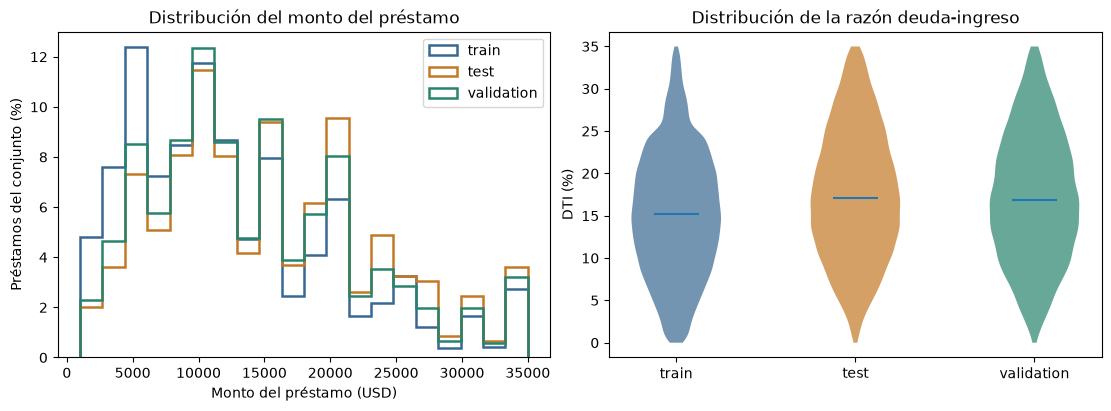

In [13]:
montos = [
    prestamos.filter(pl.col("conjunto") == c)["loan_amnt"].drop_nulls().to_numpy()
    for c in conjuntos
]
dtis = [
    prestamos.filter(pl.col("conjunto") == c)["dti"].drop_nulls().to_numpy()
    for c in conjuntos
]

fig, (ax_monto, ax_dti) = plt.subplots(
    1, 2, figsize=(11, 4), layout="constrained"
)

intervalos = np.histogram_bin_edges(np.concatenate(montos), bins=20)

for conjunto, valores in zip(conjuntos, montos):
    ax_monto.hist(
        valores,
        bins=intervalos,
        weights=np.full(len(valores), 100 / len(valores)),
        histtype="step",
        linewidth=1.8,
        color=colores[conjunto],
        label=conjunto,
    )

ax_monto.set_title("Distribución del monto del préstamo")
ax_monto.set_xlabel("Monto del préstamo (USD)")
ax_monto.set_ylabel("Préstamos del conjunto (%)")
ax_monto.legend()

violines = ax_dti.violinplot(dtis, showmedians=True, showextrema=False)
for cuerpo, conjunto in zip(violines["bodies"], conjuntos):
    cuerpo.set_facecolor(colores[conjunto])
    cuerpo.set_alpha(0.7)

ax_dti.set_xticks([1, 2, 3], conjuntos)
ax_dti.set_title("Distribución de la razón deuda-ingreso")
ax_dti.set_ylabel("DTI (%)")
plt.show()

In [14]:
resumen_variables = (
    prestamos
    .group_by("conjunto")
    .agg(
        pl.col("issue_d").min().alias("desde"),
        pl.col("loan_amnt").quantile(0.25).alias("monto_q1"),
        pl.col("loan_amnt").median().alias("monto_mediana"),
        pl.col("loan_amnt").quantile(0.75).alias("monto_q3"),
        pl.col("dti").quantile(0.25).alias("dti_q1"),
        pl.col("dti").median().alias("dti_mediana"),
        pl.col("dti").quantile(0.75).alias("dti_q3"),
    )
    .sort("desde")
    .drop("desde")
)

resumen_variables

conjunto,monto_q1,monto_mediana,monto_q3,dti_q1,dti_mediana,dti_q3
str,f64,f64,f64,f64,f64,f64
"""train""",6250.0,10375.0,17000.0,9.73,15.15,20.6
"""test""",9000.0,14750.0,20125.0,11.69,17.12,23.14
"""validation""",8000.0,12500.0,19750.0,11.36,16.84,22.76
